In [ ]:
NAME = ""
ID = ""

---

# Multimedia Processing - Tasks

*© 2018-current, authors at Computer Science and Technology, Division of Science and Technology, BNU-HKBU United International College*

**Please complete all the tasks before you submit your assignment:**
* Remove "raise NotImplementedError()" (if any) when you start to write your code.
* Fill in any place which says "YOUR CODE HERE" or "YOUR ANSWER HERE".
* In most cases, your code is a part of a function, so don't modify the function declaration which starts with "def".
* The assertion statements are for you to test your code, but your work will be evaluated using other test cases.

### Task 1 (optional)

In the code cell below, complete the function `ChessImage` which takes two integer *cubsize* and *numcub* as arguements, and returns an image of chess table. 
- The size of a unit cub is defined by `cubsize`. 
- The number of repeating pairs (one black cub + one white cub) is defined by `numcub`. 

Your chess table may look like the image below when *cubsize=50* and *numcub*=5:

<figure align="center">
    <img src="img/ch17.task1.png" width="40%">
</figure>

In [ ]:
import numpy as np
from PIL import Image

def ChessImage(cubsize,numcub):
    n = 2 * numcub
    img = np.zeros((n * cubsize, n * cubsize, 3), dtype=np.uint8)
    for i in range(n):
        for j in range(n):
            color = 255 if (i + j) % 2 == 0 else 0
            img[i*cubsize:(i+1)*cubsize, j*cubsize:(j+1)*cubsize] = color
    return Image.fromarray(img)
cubsize = 30
numcub = 5
img_chess = ChessImage(cubsize,numcub)
display(img_chess)

In [ ]:
cubsize = 30
numcub = 5
img_chess = ChessImage(cubsize,numcub)
display(img_chess)

In [ ]:
cubsize = 50
numcub = 3
img_chess = ChessImage(cubsize,numcub)
display(img_chess)

### Task 2  (optional)

In the code cell below, complete the function `SuperpsoeImage` which takes an image *Img* as an arguement, and returns a suppersposed image by overlying the image *Img* and its left-right flipped image. Your image should look like as follows:

<figure align="center">
    <img src="img/ch17.task2.png" width="70%">
</figure>

Note: *Image.blend()* are proposed to get superposed image.

In [ ]:
from PIL import Image

def SuperpsoeImage(Img):
    img_lr = Img.transpose(Image.FLIP_LEFT_RIGHT)
    return Image.blend(Img, img_lr, 0.5)

In [ ]:
Img = Image.open("data/girl.png")
Img_sup = SuperpsoeImage(Img)
display(Img_sup.convert("RGB"))

### Task 3 (optional)

In the code cell below, complete the function `AddNoise` which takes an RGB image *Img* as an arguement, and returns a new image where some image noises was added on.

In [3]:
from random import choices
import matplotlib.pyplot as plt
import numpy as np
try:
    import cv2 as cv
except ModuleNotFoundError:
    from PIL import Image
    class _CV:
        @staticmethod
        def imread(path, flag=1):
            img = Image.open(path)
            if flag == 0:
                img = img.convert('L')
            else:
                img = img.convert('RGB')
            return np.array(img)
    cv = _CV()

def AddNoise(Img):
    noise_img = Img.copy()
    if noise_img.ndim == 2:
        row, col = noise_img.shape
    else:
        row, col, _ = noise_img.shape
    num_salt = int(row * col * 0.02)
    num_pepper = int(row * col * 0.02)
    ys = np.random.randint(0, row, num_salt)
    xs = np.random.randint(0, col, num_salt)
    noise_img[ys, xs] = 255
    ys = np.random.randint(0, row, num_pepper)
    xs = np.random.randint(0, col, num_pepper)
    noise_img[ys, xs] = 0
    return noise_img

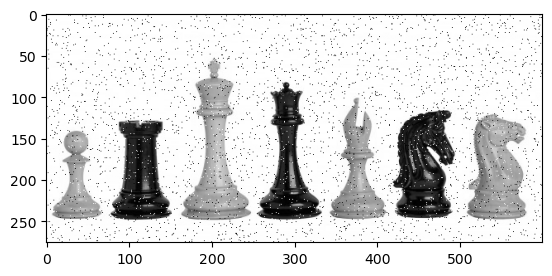

In [4]:
Img = cv.imread('data/chess pieces.jpg', 0)
Img_noise = AddNoise(Img)
plt.imshow(Img_noise,cmap='gray')
plt.show()